In [1]:
import pandas as pd
import numpy as np
import csv
import torch
import umap
import hdbscan
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df= pd.read_csv("bitcoin_tweets1000000.csv", encoding="latin1")

C:\Users\johan\AppData\Local\Temp\ipykernel_16972\3117608084.py:1: DtypeWarning: Columns (0,5,6,7,8,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv("bitcoin_tweets1000000.csv", encoding="latin1")


In [3]:
df.columns

Index(['Unnamed: 0', 'user_name', 'user_location', 'user_description',
       'user_created', 'user_followers', 'user_friends', 'user_favourites',
       'user_verified', 'date', 'text', 'hashtags', 'source', 'is_retweet',
       'cleanText', 'Polarity Score', 'sentiment'],
      dtype='object')

In [4]:
df1=df.value_counts('user_name')

In [5]:
print(df1)

user_name
Brett Murphy          7749
Hoba Bot              7075
BitcoinAgile          4857
Bitcoin updates       4463
CryptoSquawk          4448
                      ... 
Lanaya                   1
Lanang78                 1
Lanang Fauzan            1
LanaCoin.org $LANA       1
ð«ð                 1
Name: count, Length: 194081, dtype: int64


In [6]:
df1.count()

194081

c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 154 (\x9a) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128 (\x80) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 156 (\x9c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 135 (\x87) missing from font(s) 

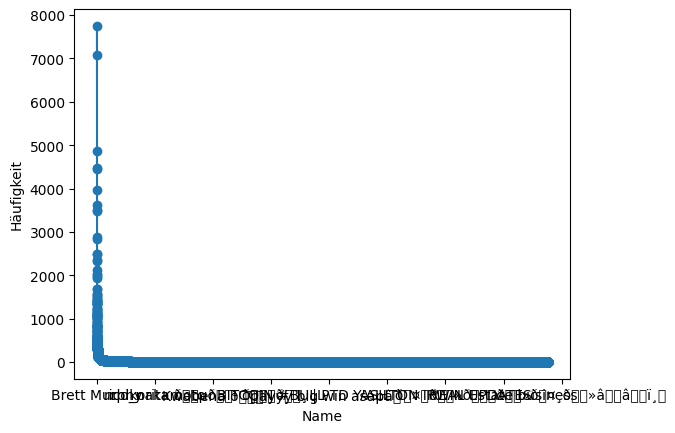

In [7]:
df1.plot(kind="line", marker="o")
plt.xlabel("Name")
plt.ylabel("Häufigkeit")
plt.show()


In [8]:
df2=df1[df1 <= 1]

In [9]:
df2.count()

109672

c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 154 (\x9a) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128 (\x80) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 156 (\x9c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 135 (\x87) missing from font(s) 

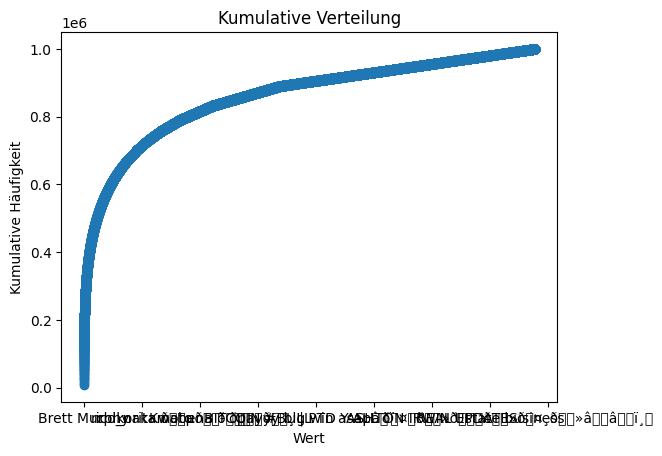

In [10]:
cum = df1.cumsum()

# Plotten
cum.plot(kind="line", marker="o")
plt.xlabel("Wert")
plt.ylabel("Kumulative Häufigkeit")
plt.title("Kumulative Verteilung")
plt.show()

In [11]:
#device = "cuda" if torch.cuda.is_available() else "cpu"
#print("Using device:", device)

#model = SentenceTransformer("all-mpnet-base-v2", device=device)
#print(model.device)

In [12]:
def build_user_text(row):
    text = str(row["cleanText"])
    bio = str(row.get("user_description", ""))

    # optional: combine bio + text
    combined = bio + " " + text
    return combined.strip()

In [13]:
df["combined_text"] = df.apply(build_user_text, axis=1)

In [14]:
#df["embedding"] = df["combined_text"].apply(lambda x: model.encode(x))
#df.to_csv("filename_latin1.csv", encoding="latin1", index=False)

In [15]:
df_result= pd.read_csv("results.csv", encoding="latin1")

C:\Users\johan\AppData\Local\Temp\ipykernel_20148\1621737473.py:1: DtypeWarning: Columns (0,5,6,7,8,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df_result= pd.read_csv("results.csv", encoding="latin1")


In [16]:
def parse_embedding(x):
    if isinstance(x, str):
        # Entfernt eckige Klammern und liest alle Zahlen per whitespace
        return np.fromstring(x.strip("[]"), sep=' ', dtype=np.float32)
    return x

In [17]:
df_result["embedding"] = df_result["embedding"].apply(parse_embedding)
user_vectors = df_result.groupby("user_name")["embedding"].apply(lambda x: np.mean(list(x), axis=0))

In [18]:
user_vectors

user_name
Authentrend                                                          [-0.008371914, 0.04588981, -0.004280068, -0.00...
Hieu                                                                 [0.00041883695, 0.053575955, 0.0011982847, 0.0...
Wutiao.Invest                                                        [0.005825184, 0.0708076, -0.03830668, -0.00715...
 'RealMoney'                                                          [0.049843844, -0.062080614, -0.015905544, -0.0...
 *Muhammad Yasir* hello stalker nice to tweet you :)                  [0.016590817, -0.04911983, -0.01382694, -0.003...
                                                                                            ...                        
ðª ð¯ðªð·ð²â ðª                                         [0.042601325, 0.053910654, -0.01601006, 0.0401...
ðª²Soulð¦                                                          [0.01721292, 0.05433618, -0.019909566, -0.0107...
ðª³ CryptoRoach ðª³         

In [31]:
len(user_vectors)

194081

In [26]:
usernames = user_vectors.index.tolist()
X = np.vstack(user_vectors.values)   # shape: (N_users, 768)

In [30]:
umap_model = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    n_components=2,
    metric="cosine",
    random_state=42
)

X_umap = umap_model.fit_transform(X)


c:\Users\johan\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


MemoryError: Allocation failed (probably too large).

In [ ]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    metric='euclidean',
    cluster_selection_method='eom'
)

labels = clusterer.fit_predict(X_umap)

In [ ]:
df_clusters = pd.DataFrame({
    "user_name": usernames,
    "cluster": labels,
    "umap_x": X_umap[:, 0], 
    "umap_y": X_umap[:, 1]
})

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(df_clusters["umap_x"], df_clusters["umap_y"], c=df_clusters["cluster"])
plt.title("User Clusters based on Tweet + Bio embeddings")
plt.show()